# Road Accident and Vehicle Data Profiling

## Overview

This notebook explores the quality and characteristics of the Victorian road crash Accident and Vehicle datasets before data cleaning and analysis.

The profiling process focuses on:

- **Structure and completeness:** Examine dataset dimensions, data types, and missing values.
- **Duplicates and identifiers:** Check duplicate records and key uniqueness.
- **Categorical attributes:** Examine category distributions and identify unusual or undocumented values.
- **Numerical attributes:** Analyse distributions, ranges, and potential outliers.
- **Data consistency and validity:** Identify logical inconsistencies and potential data quality issues.

The findings will inform the data cleaning and validation decisions in subsequent notebooks.

**Note:** This notebook is limited to data profiling. No modifications are made to the original datasets.


## Data Sources

The analysis uses two datasets from the **Victoria Road Crash Data** collection, published through the Victorian Government's open data portal.

| Dataset | Description | Level of Detail |
|---|---|---|
| Accident | Contains information about road crashes, including accident type, date, location, severity, and casualties. | One record per accident |
| Vehicle | Contains information about vehicles involved in road crashes, including vehicle characteristics, manufacture year, seating capacity, and occupants. | One record per vehicle involved |

Both datasets contain `ACCIDENT_NO`, which can be used to link vehicle records to their corresponding accidents.

## Data Sources and Dictionaries

- [Accident Dataset](https://discover.data.vic.gov.au/dataset/victoria-road-crash-data/resource/20772c1a-8b19-424a-a733-eb84f725f611)
- [Vehicle Dataset](https://discover.data.vic.gov.au/dataset/victoria-road-crash-data/resource/6d0b21f7-583a-4991-a168-f15a70c13ec4)



In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load datasets

accident_df = pd.read_csv("accident.csv", low_memory=False)
vehicle_df = pd.read_csv("vehicle.csv", low_memory=False)

print("Shape:", accident_df.shape)
print("Shape:", vehicle_df.shape)

Shape: (199699, 23)
Shape: (364297, 37)


## 1. Accident Data Profiling

### 1.1. Structure & Completeness

#### 1.1.1. Dataset overview

In [3]:
print("\nColumns:", accident_df.columns.tolist())
print("\nInfo:")
accident_df.info()


Columns: ['ACCIDENT_NO', 'ACCIDENT_DATE', 'ACCIDENT_TIME', 'ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'NODE_ID', 'NO_OF_VEHICLES', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3', 'NO_PERSONS_NOT_INJ', 'NO_PERSONS', 'POLICE_ATTEND', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC', 'SEVERITY', 'SPEED_ZONE', 'RMA']

Info:
<class 'pandas.DataFrame'>
RangeIndex: 199699 entries, 0 to 199698
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   ACCIDENT_NO         199699 non-null  str  
 1   ACCIDENT_DATE       199699 non-null  str  
 2   ACCIDENT_TIME       199699 non-null  str  
 3   ACCIDENT_TYPE       199699 non-null  int64
 4   ACCIDENT_TYPE_DESC  199699 non-null  str  
 5   DAY_OF_WEEK         199699 non-null  int64
 6   DAY_WEEK_DESC       199699 non-null  str  
 7   DCA_CODE            199699 non-null  int64
 8   DCA_DESC           

**Accident dataset** has 23 columns in total,with 199,699 entries.

#### 1.1.2. Missing Values

In [4]:
# function to check missing values
def missing_value_summary(df):
    """Summarise missing values for each attributes."""

    summary = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing (%)": (df.isna().mean() * 100).round(2)
    })

    return summary.sort_values("Missing Count", ascending=False)

In [5]:
missing_value_summary(accident_df)

,Missing Count,Missing (%)
RMA,7673,3.84
ACCIDENT_DATE,0,0.00
ACCIDENT_NO,0,0.00
ACCIDENT_TYPE,0,0.00
ACCIDENT_TYPE_DESC,0,0.00
DAY_OF_WEEK,0,0.00
ACCIDENT_TIME,0,0.00
DAY_WEEK_DESC,0,0.00
DCA_CODE,0,0.00
LIGHT_CONDITION,0,0.00


- The Accident dataset is highly complete, with most attributes containing no missing values. 
- Only `RMA` shows notable missingness, with 7,677 records (3.84%).
- Key fields such as `ACCIDENT_NO`, `ACCIDENT_DATE`, and `ACCIDENT_TIME` are complete.

### 1.2. Duplicates & Identifiers

In [6]:
# check total duplicates
print("Total duplicate rows:", accident_df.duplicated().sum())

# check duplicated key
print("Total duplicated in key:", accident_df.duplicated(subset=['ACCIDENT_NO']).sum())

Total duplicate rows: 0
Total duplicated in key: 0


- No fully duplicated records were identified.
- All `ACCIDENT_NO` values are unique, confirming that each accident is represented by a single record in the dataset.

### 1.3. Categorical Variables

In [7]:
# Accident category columns
accident_categorical = ['ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC', 'DAY_OF_WEEK', 'DAY_WEEK_DESC', 'POLICE_ATTEND',
                                'DCA_CODE', 'DCA_DESC', 'LIGHT_CONDITION', 'ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC',
                                'SEVERITY', 'SPEED_ZONE', 'RMA']

# Summarise the cardinality of categorical attributes
categorical_summary = pd.DataFrame({
    "Unique Values": accident_df[accident_categorical].nunique(dropna=True),
    "Missing Values": accident_df[accident_categorical].isna().sum()
})

categorical_summary.sort_values("Unique Values", ascending=False)

,Unique Values,Missing Values
DCA_CODE,81,0
DCA_DESC,81,0
SPEED_ZONE,13,0
ACCIDENT_TYPE_DESC,9,0
ACCIDENT_TYPE,9,0
ROAD_GEOMETRY_DESC,9,0
ROAD_GEOMETRY,9,0
DAY_OF_WEEK,8,0
DAY_WEEK_DESC,7,0
LIGHT_CONDITION,7,0


In [8]:
# Examine category frequencies, including missing values
for col in accident_categorical:
    print(f"\n{col}")

    display(
        accident_df[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )



ACCIDENT_TYPE


,Category,Count
0,1,130108
1,4,29870
2,2,16444
3,6,9287
4,8,8200
5,3,2209
6,5,2094
7,7,1272
8,9,215



ACCIDENT_TYPE_DESC


,Category,Count
0,Collision with vehicle,130108
1,Collision with a fixed object,29870
2,Struck Pedestrian,16444
3,Vehicle overturned (no collision),9287
4,No collision and no object struck,8200
5,Struck animal,2209
6,collision with some other object,2094
7,Fall from or in moving vehicle,1272
8,Other accident,215



DAY_OF_WEEK


,Category,Count
0,5,30529
1,6,30282
2,4,29831
3,3,29128
4,2,27726
5,1,25189
6,7,22430
7,0,4584


... (16 outputs left out)


SPEED_ZONE


,Category,Count
0,60,65109
1,50,32869
2,80,30291
3,100,28115
4,999,13175
5,40,12891
6,70,12507
7,110,2075
8,888,1334
9,90,503



RMA


,Category,Count
0,Arterial Other,72311
1,Local Road,69190
2,Arterial Highway,34529
3,Freeway,15917
4,NaN,7673
5,Non Arterial,77
6,Proposed Road,2


In [9]:
# Define common placeholders that may represent missing or unknown values
UNKNOWN_PATTERNS = {"?","UNKNOWN", "NOT KNOWN","NK", "UNK", "UNKN", "N/A", "NA", "NULL", "ZZ", ""}

def check_unusual_categories(df, columns):
    """Identify potential missing or unknown placeholders in categorical columns."""

    results = []

    for col in columns:
        # Standardise values for comparison without changing the original data
        values = df[col].astype("string").str.strip().str.upper()

        # Count each placeholder found in the column
        for pattern in sorted(UNKNOWN_PATTERNS):
            count = (values == pattern).sum()

            if count > 0:
                results.append({
                    "Column": col,
                    "Value": pattern,
                    "Count": int(count),
                    "Percentage (%)": round(count / len(df) * 100, 2)
                })

    # Return a consistent table even when no placeholders are found
    return pd.DataFrame(
        results,
        columns=["Column", "Value", "Count", "Percentage (%)"]
    ).sort_values("Count", ascending=False)


In [10]:
# Check potential unknown placeholders in Accident categorical attributes
accident_unusual = check_unusual_categories(accident_df, accident_categorical)
accident_unusual

,Column,Value,Count,Percentage (%)
0,ROAD_GEOMETRY_DESC,UNKNOWN,275,0.14


- `ROAD_GEOMETRY_DESC` contains 275 `UNKNOWN` values.
- `DAY_OF_WEEK` contains an undocumented code `0` in 4,584 records, while the data dictionary specifies codes `1–7`.
- `SPEED_ZONE` contains `30` and `70` km/h values, which are plausible but not listed in the current data dictionary.
- Special speed-zone codes `777` (other speed limit), `888` (camping grounds/off road), and `999` (not known) are documented categories and should not be treated as invalid values.
- `RMA` is present in the dataset but is not defined in the current Accident data dictionary. Its categories require further investigation.

### 1.4. Numerical Variables

#### 1.4.1. Descriptive Overview

In [11]:
# Select actual count variables rather than numeric identifiers
accident_numeric_cols = [
    "NO_OF_VEHICLES",
    "NO_PERSONS",
    "NO_PERSONS_KILLED",
    "NO_PERSONS_INJ_2",
    "NO_PERSONS_INJ_3",
    "NO_PERSONS_NOT_INJ"
]

# Summarise numerical distributions
accident_df[accident_numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
NO_OF_VEHICLES,199699.0,1.824240,0.744518,0.0,1.0,2.0,2.0,21.0
NO_PERSONS,199699.0,2.334353,1.449199,1.0,2.0,2.0,3.0,97.0
NO_PERSONS_KILLED,199699.0,0.017927,0.144120,0.0,0.0,0.0,0.0,5.0
NO_PERSONS_INJ_2,199699.0,0.416837,0.623711,0.0,0.0,0.0,1.0,15.0
NO_PERSONS_INJ_3,199699.0,0.864807,0.786419,0.0,0.0,1.0,1.0,43.0
NO_PERSONS_NOT_INJ,199699.0,1.034782,1.224780,0.0,0.0,1.0,1.0,94.0


- All six numerical attributes contain 199,699 non-null observations.
- The median accident involves 2 vehicles and 2 persons.
- Most casualty-related variables have relatively low typical counts, while their maximum values are considerably higher, suggesting potential right-skewed distributions.
- `NO_OF_VEHICLES` ranges from 0 to 21, including records reporting no vehicles.
- `NO_PERSONS` ranges from 1 to 97, indicating a small number of potentially unusual high-count records.

#### 1.4.2. Distribution and Outlier Analysis

In [12]:
def plot_distribution(df, column, title, bin):
    """Visualise a numerical distribution using a histogram and boxplot."""

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Plot histogram
    df[column].plot(
        kind="hist",
        bins=bin,
        ax=axes[0]
    )
    axes[0].set_title(f"Distribution of {title}")
    axes[0].set_xlabel(title)
    axes[0].set_ylabel("Frequency")

    # Plot boxplot
    df.boxplot(
        column=column,
        ax=axes[1]
    )
    axes[1].set_title(f"Boxplot of {title}")
    axes[1].set_ylabel(title)

    plt.tight_layout()
    plt.show()


##### **1. Number of vehicles (`NO_OF_VEHICLES`)**

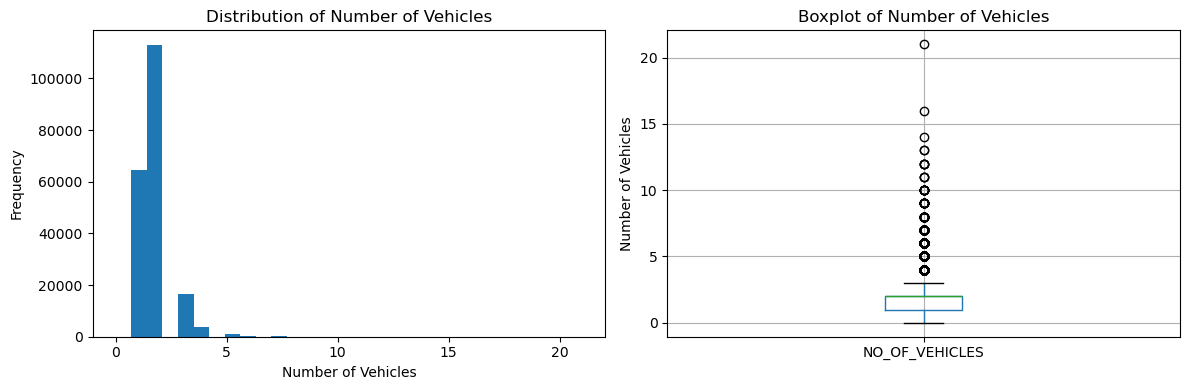

In [13]:
plot_distribution(
    accident_df,
    'NO_OF_VEHICLES',
    'Number of Vehicles',
    30
)

In [14]:
# Inspect accidents with unusually high vehicle counts.
accident_df.loc[
    accident_df['NO_OF_VEHICLES'] > 5,
    [
        'ACCIDENT_NO',
        'ACCIDENT_TYPE_DESC',
        'DCA_DESC',
        'NO_OF_VEHICLES',
        'NO_PERSONS',
        'SEVERITY'
    ]
].sort_values('NO_OF_VEHICLES', ascending=False)

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,DCA_DESC,NO_OF_VEHICLES,NO_PERSONS,SEVERITY
17340,T20160000627,Collision with vehicle,LANE SIDE SWIPE (VEHICLES IN PARALLEL LANES),21,28,3
144052,T20120003766,Collision with vehicle,REAR END(VEHICLES IN SAME LANE),16,17,2
57154,T20150006101,Collision with vehicle,VEHICLE COLLIDES WITH VEHICLE PARKED ON LEFT O...,14,10,2
46270,T20210002102,Collision with vehicle,REAR END(VEHICLES IN SAME LANE),13,23,2
58407,T20120000190,Collision with vehicle,REAR END(VEHICLES IN SAME LANE),13,13,3
...,...,...,...,...,...,...
114663,T20120024432,Collision with vehicle,ACCIDENT OR BROKEN DOWN,6,6,3
114313,T20190018150,Collision with vehicle,PARKED CAR RUN AWAY,6,1,3
113733,T20230008653,Collision with vehicle,VEHICLE COLLIDES WITH VEHICLE PARKED ON LEFT O...,6,2,2
112808,T20150018830,Collision with vehicle,REAR END(VEHICLES IN SAME LANE),6,6,3


In [15]:
# Inspect accidents with vehicle counts = 0.
accident_df.loc[
    accident_df['NO_OF_VEHICLES'] == 0,
    [
        'ACCIDENT_NO',
        'ACCIDENT_TYPE_DESC',
        'DCA_DESC',
        'NO_OF_VEHICLES',
        'NO_PERSONS',
        'SEVERITY'
    ]
].sort_values('NO_OF_VEHICLES', ascending=False)

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,DCA_DESC,NO_OF_VEHICLES,NO_PERSONS,SEVERITY
48927,T20200012731,Vehicle overturned (no collision),OUT OF CONTROL ON CARRIAGEWAY (ON STRAIGHT),0,1,2
62271,T20220002330,Collision with a fixed object,RIGHT OFF CARRIAGEWAY INTO OBJECT/PARKED VEHICLE,0,1,3
62428,T20200008868,Vehicle overturned (no collision),OUT OF CONTROL ON CARRIAGEWAY (ON STRAIGHT),0,1,2
127646,T20190002653,Vehicle overturned (no collision),OUT OF CONTROL ON CARRIAGEWAY (ON STRAIGHT),0,1,3
142959,T20230030888,Vehicle overturned (no collision),OUT OF CONTROL ON CARRIAGEWAY (ON STRAIGHT),0,1,3
162351,T20230027118,Vehicle overturned (no collision),OUT OF CONTROL ON CARRIAGEWAY (ON STRAIGHT),0,1,2


**Findings**

- Most accidents involve 1-2 vehicles, so the distribution is highly right-skewed.
- A small number of records show high vehicle counts, with the maximum reaching 21 vehicles.
- After reviewing accidents with more than five vehicles, these records appear plausible rather than obviously incorrect.
- However, 6 accidents report `NO_OF_VEHICLES = 0`. 5 are classified as vehicle overturning accidents and one as a collision with a fixed object. All six involve one person.

**Cleaning Implications**

- Keep the high vehicle-count records for now.
- Check the zero-vehicle records against the Vehicle dataset in the cross-dataset validation step.

##### **2. Number of Persons (`NO_PERSONS`)**

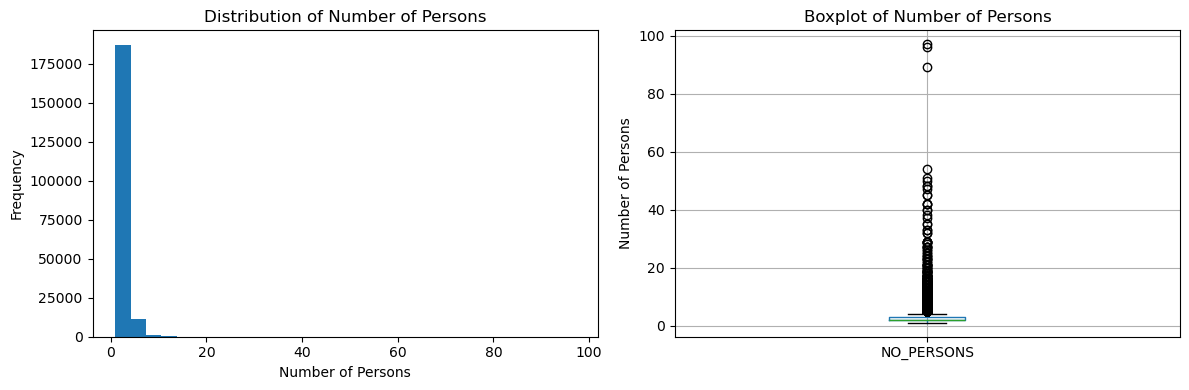

In [16]:
plot_distribution(
    accident_df,
    'NO_PERSONS',
    'Number of Persons',
    30
)

In [17]:
accident_df.loc[
    accident_df['NO_PERSONS'] > 20,
    [
        'ACCIDENT_NO',
        'ACCIDENT_TYPE_DESC',
        'NO_OF_VEHICLES',
        'NO_PERSONS',
        'NO_PERSONS_KILLED',
        'NO_PERSONS_INJ_2',
        'NO_PERSONS_INJ_3',
        'NO_PERSONS_NOT_INJ'
    ]
].sort_values('NO_PERSONS', ascending=False)

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,NO_OF_VEHICLES,NO_PERSONS,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,NO_PERSONS_NOT_INJ
12998,T20130018492,Collision with vehicle,2,97,0,1,9,87
85272,T20240013942,Collision with vehicle,3,96,0,1,1,94
1426,T20150016376,Collision with vehicle,2,89,0,1,1,87
161183,T20170009983,Collision with vehicle,2,54,0,7,16,31
64398,T20190012874,Vehicle overturned (no collision),2,51,1,4,43,3
152963,T20140009807,Collision with vehicle,2,50,0,1,8,41
49117,T20150014941,Collision with vehicle,2,48,0,1,0,47
137379,T20150020583,Collision with vehicle,2,48,0,1,14,33
140721,T20230011453,Collision with vehicle,2,47,0,7,39,1
52927,T20220018463,Collision with vehicle,4,45,1,3,0,41



**Findings**

- The distribution is strongly right-skewed, with most accidents involving relatively few people (median = 2).
- The maximum recorded value is 97 persons. Several high-count accidents involve only 2-3 vehicles, which warrants further investigation.
- The displayed extreme records have casualty breakdowns consistent with the reported total number of persons. However, this does not confirm the accuracy of the original counts.
- High person counts may reflect vehicles carrying many passengers, but this cannot be confirmed from the Accident dataset alone.

**Data Quality Implications**

- Retain extreme person counts unless further validation identifies errors.
- Review vehicle characteristics for unusually high-person-count accidents during cross-dataset validation.
- Validate person-count consistency across the full Accident dataset in Section 1.5.


##### **Number of Lives lost (`NO_PERSONS_KILLED`)**

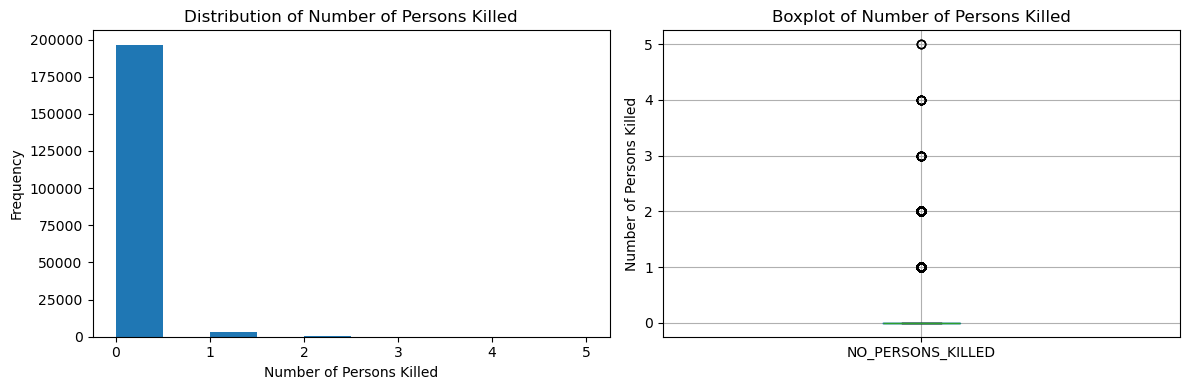

In [18]:
plot_distribution(
    accident_df,
    'NO_PERSONS_KILLED',
    'Number of Persons Killed',
    10
)

In [19]:
accident_df.loc[
    accident_df['NO_PERSONS_KILLED'] > 2,
    ['ACCIDENT_NO',
                'ACCIDENT_TYPE_DESC',
                'NO_OF_VEHICLES',
                'NO_PERSONS',
                'NO_PERSONS_KILLED',
                'SEVERITY']
].sort_values('NO_PERSONS_KILLED',ascending=False)

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,NO_OF_VEHICLES,NO_PERSONS,NO_PERSONS_KILLED,SEVERITY
26821,T20230025958,Struck Pedestrian,1,12,5,1
31791,T20230009235,Collision with vehicle,3,8,5,1
182819,T20120027574,Collision with vehicle,2,7,5,1
21411,T20230000231,Collision with vehicle,2,6,4,1
33890,T20140004201,Collision with vehicle,2,6,4,1
11141,T20150001921,Collision with a fixed object,1,4,4,1
5785,T20140004905,Collision with vehicle,2,7,4,1
81590,T20180008548,Collision with vehicle,2,5,4,1
133793,T20210020087,Collision with vehicle,2,7,4,1
182485,T20230020377,Collision with vehicle,2,5,4,1



**Findings**

- Most accidents report zero fatalities, with a maximum of five fatalities recorded in a single accident.
- Accidents involving more than two fatalities are uncommon and occur across different accident types.
- All displayed high-fatality records are classified as `SEVERITY = 1` (fatal accidents), consistent with their reported fatality counts.
- The reported fatalities do not exceed the total number of persons involved in the displayed records.

**Data Quality Implications**

- High fatality counts do not indicate obvious inconsistencies in the reviewed records and should be retained.
- Severity and casualty-count consistency will be validated across the full dataset in Section 1.5.


##### **Number of Person/s with Serious Injury (`NO_PERSONS_INJ_2`)**

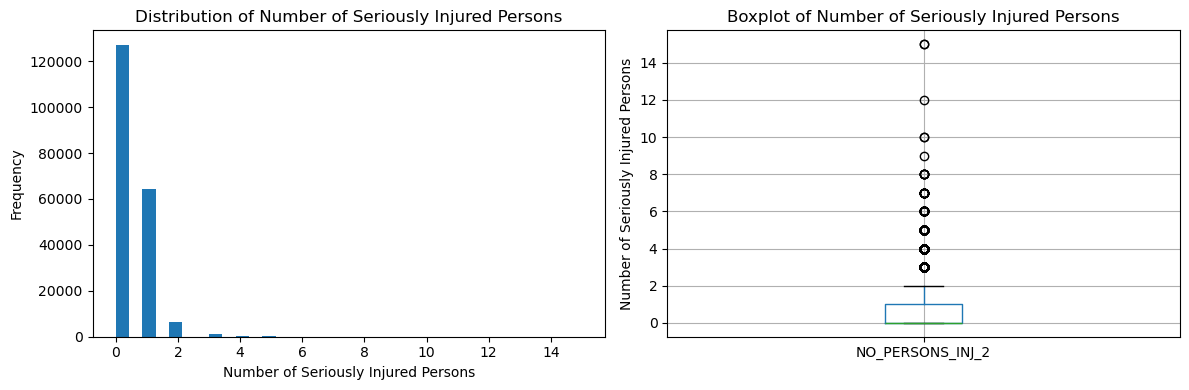

In [20]:
plot_distribution(
    accident_df,
    'NO_PERSONS_INJ_2',
    'Number of Seriously Injured Persons',
    35
)

In [21]:
accident_df.loc[
    accident_df['NO_PERSONS_INJ_2'] > 10,
    ['ACCIDENT_NO',
                'ACCIDENT_TYPE_DESC',
                'NO_OF_VEHICLES',
                'NO_PERSONS',
                 'NO_PERSONS_KILLED',
                'NO_PERSONS_INJ_2',
                'SEVERITY']
].sort_values('NO_PERSONS_INJ_2',ascending=False)

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,NO_OF_VEHICLES,NO_PERSONS,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,SEVERITY
87311,T20220021349,Collision with vehicle,2,33,0,15,2
154616,T20170019583,Vehicle overturned (no collision),1,29,2,15,1
62694,T20250022712,Collision with a fixed object,1,32,1,12,1


**Findings**

- Most accidents report zero or one seriously injured person, with a maximum of 15.
- Three accidents record more than 10 serious injuries.
- All three records have serious injury counts within the reported total number of persons.
- Two of these accidents are classified as fatal (`SEVERITY = 1`), with additional fatalities recorded. This is consistent with the severity classification.

**Data Quality Implications**

- The reviewed extreme values show no obvious inconsistencies and should be retained.
- Casualty totals and severity classifications will be further validated across the full dataset in Section 1.5.


##### **Number of Person/s with other injury (`NO_PERSONS_INJ_3`)**

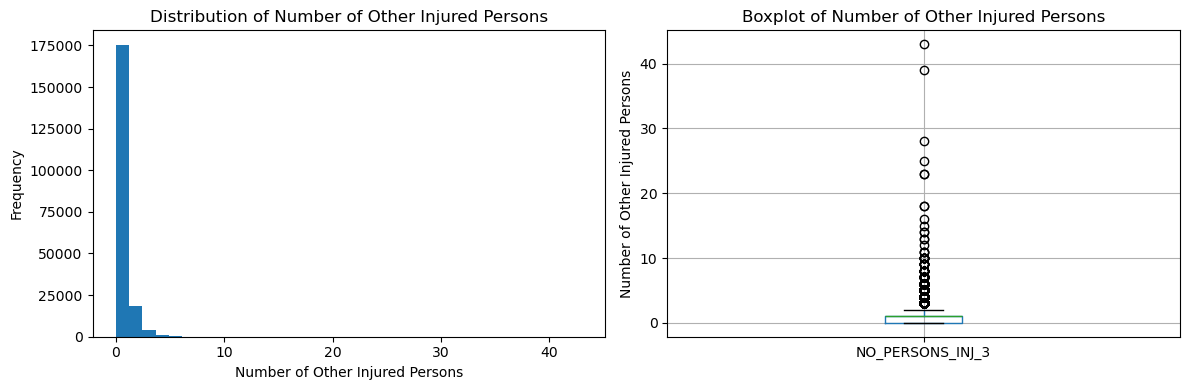

In [22]:
plot_distribution(
    accident_df,
    'NO_PERSONS_INJ_3',
    'Number of Other Injured Persons',
    35
)

In [23]:
accident_df.loc[
    accident_df['NO_PERSONS_INJ_3'] > 20,
    ['ACCIDENT_NO',
                'ACCIDENT_TYPE_DESC',
                'NO_OF_VEHICLES',
                'NO_PERSONS',
                 'NO_PERSONS_KILLED',
                 'NO_PERSONS_INJ_2',
                'NO_PERSONS_INJ_3',
                'SEVERITY']
].sort_values('NO_PERSONS_INJ_3',ascending=False)

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,NO_OF_VEHICLES,NO_PERSONS,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,SEVERITY
64398,T20190012874,Vehicle overturned (no collision),2,51,1,4,43,1
140721,T20230011453,Collision with vehicle,2,47,0,7,39,2
124612,T20220023662,Collision with a fixed object,1,29,0,0,28,3
15036,T20150023627,Collision with vehicle,2,27,1,1,25,1
19739,T20200001577,Vehicle overturned (no collision),1,25,0,1,23,2
27469,T20140015029,Collision with a fixed object,1,27,0,0,23,3



**Findings**

- Most accidents report zero or one person with injury level 3, with a maximum of 43.
- Six accidents record more than 20 persons in this injury category, across different accident types.
- The reviewed records show no obvious inconsistencies between injury counts, total persons, and severity classifications.
- High injury counts may reflect genuine multi-person accidents, although their accuracy cannot be confirmed from these records alone.

**Data Quality Implications**

- Retain the extreme injury counts unless further validation identifies errors.
- Validate casualty totals and severity classifications across the full Accident dataset in Section 1.5.


### 1.5. Data Consistency & Validity

#### 1.5.1. Code mapping

In [24]:
pairs_check = [
    ('ACCIDENT_TYPE', 'ACCIDENT_TYPE_DESC'),
    ('DAY_OF_WEEK', 'DAY_WEEK_DESC'),
    ('DCA_CODE', 'DCA_DESC'),
    ('ROAD_GEOMETRY', 'ROAD_GEOMETRY_DESC')
]

for code_col, desc_col in pairs_check:
    print(f"\n{code_col} vs {desc_col}")
    consistency_check = (
        accident_df[[code_col, desc_col]]
        .drop_duplicates()
        .sort_values(code_col))
    display(consistency_check)


ACCIDENT_TYPE vs ACCIDENT_TYPE_DESC


,ACCIDENT_TYPE,ACCIDENT_TYPE_DESC
1,1,Collision with vehicle
3,2,Struck Pedestrian
51,3,Struck animal
26,4,Collision with a fixed object
162,5,collision with some other object
18,6,Vehicle overturned (no collision)
0,7,Fall from or in moving vehicle
20,8,No collision and no object struck
1054,9,Other accident



DAY_OF_WEEK vs DAY_WEEK_DESC


,DAY_OF_WEEK,DAY_WEEK_DESC
31,0,Sunday
6,1,Sunday
38,1,Monday
10,2,Monday
24,2,Tuesday
29,3,Wednesday
4,3,Tuesday
0,4,Wednesday
2,4,Thursday
20,5,Thursday



DCA_CODE vs DCA_DESC


,DCA_CODE,DCA_DESC
3,100,PED NEAR SIDE. PED HIT BY VEHICLE FROM THE RIGHT.
274,101,PED EMERGES FROM IN FRONT OF PARKED OR STATION...
17,102,FAR SIDE. PED HIT BY VEHICLE FROM THE LEFT
480,103,PED PLAYING/LYING/WORKING/STANDING ON CARRIAGE...
977,104,PED WALKING WITH TRAFFIC
...,...,...
1426,192,STRUCK TRAIN
203,193,STRUCK RAILWAY CROSSING FURNITURE
1346,194,PARKED CAR RUN AWAY
29,198,OTHER ACCIDENTS NOT CLASSIFIABLE ELSEWHERE



ROAD_GEOMETRY vs ROAD_GEOMETRY_DESC


,ROAD_GEOMETRY,ROAD_GEOMETRY_DESC
0,1,Cross intersection
12,2,T intersection
4,3,Y intersection
2,4,Multiple intersection
1,5,Not at intersection
827,6,Dead end
4860,7,Road closure
21299,8,Private property
1545,9,Unknown



**Findings**

- No code-description mapping inconsistencies were identified for `ACCIDENT_TYPE`, `DCA_CODE`, or `ROAD_GEOMETRY`.
- `DAY_OF_WEEK` contains inconsistent mappings, with some codes associated with multiple weekday descriptions.
- The undocumented code `DAY_OF_WEEK = 0` was also identified during categorical profiling.

**Data Quality Implications**

- Correct inconsistent `DAY_OF_WEEK` values using the corresponding `DAY_WEEK_DESC` values and the documented weekday code mapping during data cleaning.

#### 1.5.2. Logic Check

In [25]:
# Check whether total persons equals the sum of reported person outcomes.
calculated_persons = (
    accident_df['NO_PERSONS_KILLED']
    + accident_df['NO_PERSONS_INJ_2']
    + accident_df['NO_PERSONS_INJ_3']
    + accident_df['NO_PERSONS_NOT_INJ']
)

person_mismatch = accident_df[
    accident_df['NO_PERSONS'] != calculated_persons
]

print("Person count mismatches:", len(person_mismatch))


Person count mismatches: 0



**Findings**

- No mismatches were identified between `NO_PERSONS` and the sum of the four casualty outcome categories.
- The reported person totals are internally consistent across the Accident dataset.

**Data Quality Implications**

- No correction to person totals is required based on this check.

In [26]:
severity_mismatch = accident_df[
    # Severity 1: Fatal accident must have at least one killed person
    ((accident_df['SEVERITY'] == 1) &
     (accident_df['NO_PERSONS_KILLED'] == 0))

    |

    # Severity 2: No fatalities, but at least one serious injury
    ((accident_df['SEVERITY'] == 2) &
     (
         (accident_df['NO_PERSONS_KILLED'] > 0) |
         (accident_df['NO_PERSONS_INJ_2'] == 0)
     ))

    |

    # Severity 3: No fatal/serious injuries, but at least one other injury
    ((accident_df['SEVERITY'] == 3) &
     (
         (accident_df['NO_PERSONS_KILLED'] > 0) |
         (accident_df['NO_PERSONS_INJ_2'] > 0) |
         (accident_df['NO_PERSONS_INJ_3'] == 0)
     ))

    |

    # Severity 4: No recorded injuries or fatalities
    ((accident_df['SEVERITY'] == 4) &
     (
         (accident_df['NO_PERSONS_KILLED'] > 0) |
         (accident_df['NO_PERSONS_INJ_2'] > 0) |
         (accident_df['NO_PERSONS_INJ_3'] > 0)
     ))
]

print("Severity-outcome mismatches:", len(severity_mismatch))
severity_mismatch[['ACCIDENT_NO','SEVERITY', 'NO_PERSONS_KILLED', 'NO_PERSONS_INJ_2', 'NO_PERSONS_INJ_3']]

Severity-outcome mismatches: 9


,ACCIDENT_NO,SEVERITY,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3
27975,T20210002562,3,0,1,0
39844,T20210010821,3,0,1,0
81879,T20210025034,3,0,0,0
82403,T20210014197,3,0,1,0
97374,T20230029194,3,0,0,0
108249,T20240007400,2,0,0,1
171062,T20230001286,3,0,0,0
190105,T20230010484,3,0,0,0
199463,T20200003573,3,0,0,0



**Findings**

- Nine records were identified with inconsistencies between `SEVERITY` and the reported casualty outcomes.
- These records do not satisfy the expected severity-outcome conditions.

**Data Quality Implications**

- Flag the inconsistent records for data quality review.
- Preserve the original severity and casualty values rather than automatically correcting them, as the source of the inconsistency cannot be determined from these fields alone.


## 2. Vehicle Data Profiling

### 2.1. Structure & Completeness

#### 2.1.1. Dataset Overview

In [27]:
print("\nColumns:", vehicle_df.columns.tolist())
print("\nInfo:")
vehicle_df.info()


Columns: ['ACCIDENT_NO', 'VEHICLE_ID', 'VEHICLE_YEAR_MANUF', 'VEHICLE_DCA_CODE', 'INITIAL_DIRECTION', 'ROAD_SURFACE_TYPE', 'ROAD_SURFACE_TYPE_DESC', 'REG_STATE', 'VEHICLE_BODY_STYLE', 'VEHICLE_MAKE', 'VEHICLE_MODEL', 'VEHICLE_POWER', 'VEHICLE_TYPE', 'VEHICLE_TYPE_DESC', 'VEHICLE_WEIGHT', 'CONSTRUCTION_TYPE', 'FUEL_TYPE', 'NO_OF_WHEELS', 'NO_OF_CYLINDERS', 'SEATING_CAPACITY', 'TARE_WEIGHT', 'TOTAL_NO_OCCUPANTS', 'CARRY_CAPACITY', 'CUBIC_CAPACITY', 'FINAL_DIRECTION', 'DRIVER_INTENT', 'VEHICLE_MOVEMENT', 'TRAILER_TYPE', 'VEHICLE_COLOUR_1', 'VEHICLE_COLOUR_2', 'CAUGHT_FIRE', 'INITIAL_IMPACT', 'LAMPS', 'LEVEL_OF_DAMAGE', 'TOWED_AWAY_FLAG', 'TRAFFIC_CONTROL', 'TRAFFIC_CONTROL_DESC']

Info:
<class 'pandas.DataFrame'>
RangeIndex: 364297 entries, 0 to 364296
Data columns (total 37 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ACCIDENT_NO             364297 non-null  str    
 1   VEHICLE_ID              364297 non-null

**Vehicle dataset** has 37 columns in total, with 364,297 entries.

#### 2.1.2. Missing Values

In [28]:
missing_value_summary(vehicle_df)

,Missing Count,Missing (%)
VEHICLE_POWER,364297,100.00
CARRY_CAPACITY,318091,87.32
VEHICLE_WEIGHT,317910,87.27
CUBIC_CAPACITY,313446,86.04
CONSTRUCTION_TYPE,71709,19.68
SEATING_CAPACITY,62818,17.24
NO_OF_WHEELS,45697,12.54
NO_OF_CYLINDERS,38080,10.45
VEHICLE_MODEL,33989,9.33
VEHICLE_BODY_STYLE,28242,7.75



**Findings**

- `VEHICLE_POWER` is entirely missing (100%), providing no usable information for analysis.
- `CARRY_CAPACITY` (87.32%), `VEHICLE_WEIGHT` (87.27%), and `CUBIC_CAPACITY` (86.04%) have very high missing rates, limiting their analytical usefulness.
- Several vehicle characteristics have moderate missing rates, including `CONSTRUCTION_TYPE` (19.68%), `SEATING_CAPACITY` (17.24%), `NO_OF_WHEELS` (12.54%), and `NO_OF_CYLINDERS` (10.45%).
- `VEHICLE_YEAR_MANUF` has 1.91% missing values, while `TOTAL_NO_OCCUPANTS` has only 31 missing records (0.01%).
- Key identifiers, `ACCIDENT_NO` and `VEHICLE_ID`, contain no missing values.

**Data Quality Implications**

- Exclude `VEHICLE_POWER` from further analysis due to its complete absence of data.
- Review the relevance of attributes with very high missing rates before deciding whether to retain them.
- Consider appropriate treatment for missing vehicle characteristics based on their data types, analytical importance, and vehicle applicability.

### 2.2. Duplicates & Identifiers

In [29]:
print("Number of duplicate rows:",
      vehicle_df.duplicated().sum())

print("Number of duplicate composite keys:",
      vehicle_df.duplicated(
          subset=['ACCIDENT_NO', 'VEHICLE_ID']
      ).sum())

print("Number of unique composite keys:",
      vehicle_df[['ACCIDENT_NO', 'VEHICLE_ID']]
      .drop_duplicates()
      .shape[0])

Number of duplicate rows: 0
Number of duplicate composite keys: 0
Number of unique composite keys: 364297


- No fully duplicated records were identified.
- The composite key (`ACCIDENT_NO`, `VEHICLE_ID`) is unique across all 364,297 vehicle records.

### 2.3. Categorical Variables

In [30]:
# Descriptive categorical attributes
vehicle_categorical_cols = [
    "INITIAL_DIRECTION",
    "ROAD_SURFACE_TYPE_DESC",
    "REG_STATE",
    "VEHICLE_TYPE_DESC",
    "CONSTRUCTION_TYPE",
    "FUEL_TYPE",
    "FINAL_DIRECTION",
    "TRAILER_TYPE",
    "VEHICLE_COLOUR_1",
    "VEHICLE_COLOUR_2",
    "INITIAL_IMPACT",
    "TRAFFIC_CONTROL_DESC"
]

# Coded categorical attributes
vehicle_coded_cols = [
    "VEHICLE_DCA_CODE",
    "ROAD_SURFACE_TYPE",
    "VEHICLE_TYPE",
    "DRIVER_INTENT",
    "VEHICLE_MOVEMENT",
    "CAUGHT_FIRE",
    "LAMPS",
    "LEVEL_OF_DAMAGE",
    "TOWED_AWAY_FLAG",
    "TRAFFIC_CONTROL"
]

# Combine categorical attributes for profiling
vehicle_all_categorical = (vehicle_categorical_cols + vehicle_coded_cols)

In [31]:
# Summarise categorical cardinality and completeness
vehicle_category_summary = pd.DataFrame({
    "Unique Values": vehicle_df[vehicle_all_categorical].nunique(dropna=True),
    "Missing Values": vehicle_df[vehicle_all_categorical].isna().sum()})
vehicle_category_summary

,Unique Values,Missing Values
INITIAL_DIRECTION,9,1
ROAD_SURFACE_TYPE_DESC,4,1
REG_STATE,11,22365
VEHICLE_TYPE_DESC,29,0
CONSTRUCTION_TYPE,3,71709
FUEL_TYPE,8,20052
FINAL_DIRECTION,9,1
TRAILER_TYPE,12,31
VEHICLE_COLOUR_1,18,0
VEHICLE_COLOUR_2,17,24


In [32]:
# Inspect category frequencies, including missing values
for col in vehicle_all_categorical:
    print(f"\n{col}")

    display(
        vehicle_df[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )


INITIAL_DIRECTION


,Category,Count
0,S,57040
1,N,56422
2,E,55565
3,W,54724
4,SE,36480
5,NW,35112
6,NE,31213
7,SW,30832
8,NK,6908
9,NaN,1



ROAD_SURFACE_TYPE_DESC


,Category,Count
0,Paved,345931
1,Gravel,13037
2,Not known,3184
3,Unpaved,2144
4,NaN,1



REG_STATE


,Category,Count
0,V,324036
1,NaN,22365
2,Z,9072
3,N,3716
4,Q,1936
5,S,1790
6,W,578
7,T,403
8,A,302
9,D,96


... (34 outputs left out)


TOWED_AWAY_FLAG


,Category,Count
0,1.0,171831
1,2.0,165938
2,9.0,26525
3,NaN,3



TRAFFIC_CONTROL


,Category,Count
0,0.0,224845
1,1.0,69343
2,11.0,22757
3,9.0,14650
4,99.0,14321
5,10.0,7895
6,15.0,4513
7,5.0,2800
8,4.0,898
9,14.0,579


In [33]:
# Identify potential unknown placeholders in Vehicle categorical attributes
vehicle_unusual = check_unusual_categories(
    vehicle_df,
    vehicle_categorical_cols
)

vehicle_unusual

,Column,Value,Count,Percentage (%)
5,VEHICLE_COLOUR_2,ZZ,355821,97.67
4,VEHICLE_COLOUR_1,ZZ,28330,7.78
3,FINAL_DIRECTION,NK,16953,4.65
6,TRAFFIC_CONTROL_DESC,UNKNOWN,14321,3.93
0,INITIAL_DIRECTION,NK,6908,1.90
2,VEHICLE_TYPE_DESC,NOT KNOWN,6539,1.79
1,ROAD_SURFACE_TYPE_DESC,NOT KNOWN,3184,0.87



**Findings**

- Potential unknown-value placeholders were identified across multiple categorical attributes.
- `INITIAL_DIRECTION` contains 6,908 `NK` values, while `FINAL_DIRECTION` contains 16,953.
- `ROAD_SURFACE_TYPE_DESC` contains 3,184 `Not known` values, and `VEHICLE_TYPE_DESC` contains 6,539 `Not Known` values.
- `VEHICLE_COLOUR_2` contains 355,821 `ZZ` values, indicating that a second vehicle colour is rarely specified.
- `TRAFFIC_CONTROL_DESC` contains 14,321 `Unknown` values.


**Data Quality Implications**

- Standardise different representations of unknown values (e.g., `NK`, `ZZ`, `Not Known`, and `Unknown`) into a consistent `UNKNOWN` category during data cleaning.

##### **Vehicle Type Description (`VEHICLE_TYPE_DESC`)**

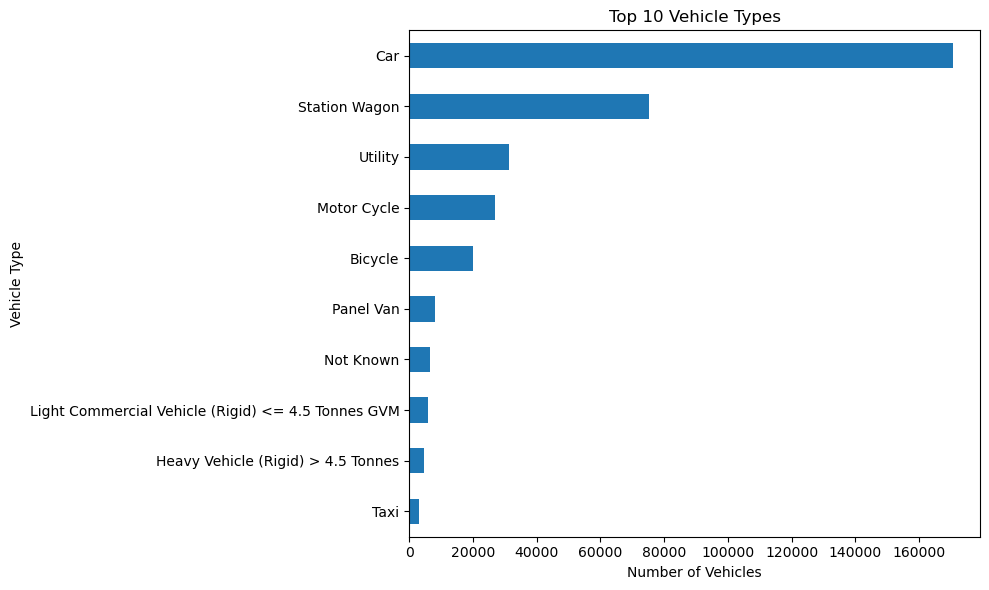

In [34]:
vehicle_type_counts = (
    vehicle_df['VEHICLE_TYPE_DESC']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))
vehicle_type_counts.sort_values().plot(kind='barh')

plt.title('Top 10 Vehicle Types')
plt.xlabel('Number of Vehicles')
plt.ylabel('Vehicle Type')
plt.tight_layout()

plt.show()

- Cars are the most common vehicle type, accounting for 170,568 records, followed by station wagons (75,246).
- Utilities (31,442), motorcycles (26,874), and bicycles (19,922) are also frequently represented.
- The dataset includes a diverse range of vehicle types, from passenger vehicles to heavy vehicles and public transport.

##### **Road Surface Type Description (`ROAD_SURFACE_TYPE_DESC`)**

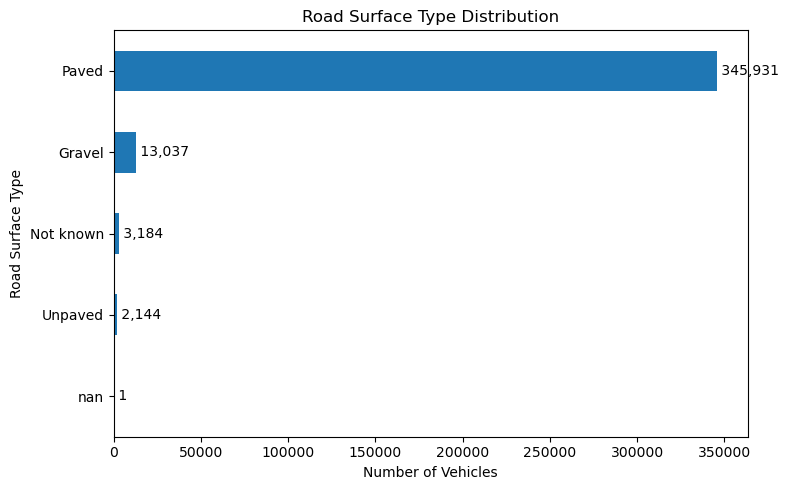

In [35]:
road_surface_counts = (
    vehicle_df['ROAD_SURFACE_TYPE_DESC']
    .value_counts(dropna=False)
)

ax = road_surface_counts.sort_values().plot(
    kind='barh',
    figsize=(8, 5)
)

plt.title('Road Surface Type Distribution')
plt.xlabel('Number of Vehicles')
plt.ylabel('Road Surface Type')

for i, value in enumerate(road_surface_counts.sort_values()):
    ax.text(value, i, f' {value:,}', va='center')

plt.tight_layout()
plt.show()

- Paved roads dominate the records, accounting for 345,931 vehicles.
- Gravel (13,037) and unpaved surfaces (2,144) are much less common.
- Road surface information is recorded as `Not known` for 3,184 vehicles, with one additional null value.

##### **Traffic Control Description (`TRAFFIC_CONTROL_DESC`)**

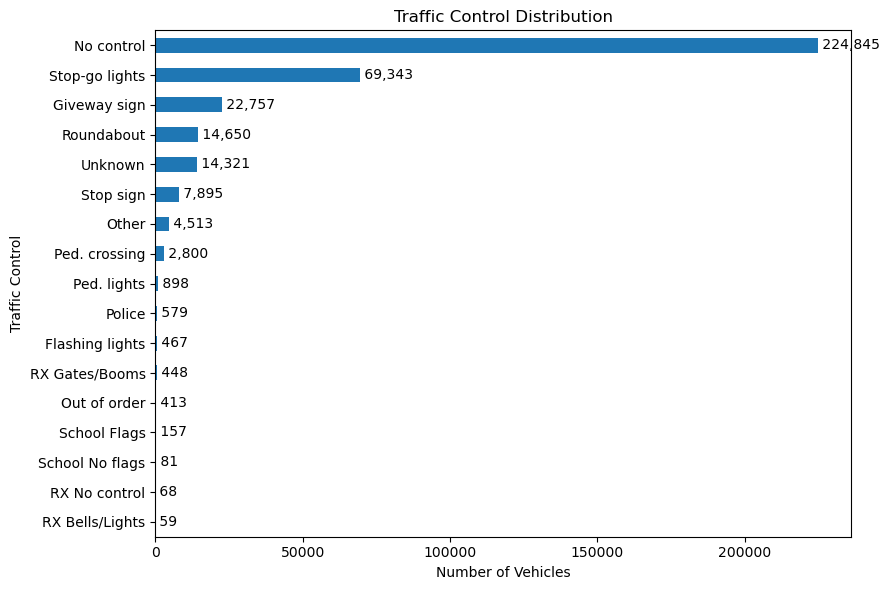

In [36]:
traffic_control_counts = (
    vehicle_df['TRAFFIC_CONTROL_DESC']
    .value_counts()
)

ax = traffic_control_counts.sort_values().plot(
    kind='barh',
    figsize=(9, 6)
)

plt.title('Traffic Control Distribution')
plt.xlabel('Number of Vehicles')
plt.ylabel('Traffic Control')

for i, value in enumerate(traffic_control_counts.sort_values()):
    ax.text(value, i, f' {value:,}', va='center')

plt.tight_layout()
plt.show()

- `No control` is the most common category, accounting for 224,845 vehicle records.
- `Stop-go lights` (69,343), `Giveway sign` (22,757), and `Roundabout` (14,650) are also frequently recorded.
- Traffic control is classified as `Unknown` in 14,321 records, with three additional null values.

### 2.4. Numerical Variables & Outliers

#### 2.4.1. Descriptive Overview

In [37]:
# numeric columns
num_col = [
    col for col in vehicle_df.select_dtypes(include=['float64', 'int64'])
    if col not in vehicle_coded_cols
]

vehicle_df[num_col].describe().T

,count,mean,std,min,25%,50%,75%,max
VEHICLE_YEAR_MANUF,357346.0,1833.810086,566.009193,0.0,2002.0,2008.0,2014.0,3001.0
VEHICLE_POWER,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VEHICLE_WEIGHT,46387.0,5582.644685,7297.778384,251.0,2494.5,2850.0,3300.0,340000.0
NO_OF_WHEELS,318600.0,3.898095,0.682240,1.0,4.0,4.0,4.0,46.0
NO_OF_CYLINDERS,326217.0,4.465761,1.356286,1.0,4.0,4.0,6.0,93.0
SEATING_CAPACITY,301479.0,5.041781,2.936529,1.0,5.0,5.0,5.0,74.0
TARE_WEIGHT,352330.0,1553.553867,1701.366989,0.0,1100.0,1400.0,1684.0,96000.0
TOTAL_NO_OCCUPANTS,364266.0,1.243437,0.830719,0.0,1.0,1.0,1.0,96.0
CARRY_CAPACITY,46206.0,2462.308856,4472.577128,1.0,705.0,1030.0,1375.0,323060.0
CUBIC_CAPACITY,50851.0,1779.714519,1444.699568,1.0,600.0,1584.0,2500.0,9900.0


- `VEHICLE_YEAR_MANUF` ranges from 0 to 3001, indicating potentially invalid manufacture years. Its mean (1833.81) is substantially lower than the median (2008), suggesting that unusual low values distort the average.
- `NO_OF_CYLINDERS` reaches 93 and `NO_OF_WHEELS` reaches 46, requiring further review against vehicle types.
- `SEATING_CAPACITY` reaches 74, while `TOTAL_NO_OCCUPANTS` reaches 96. These extreme values may be plausible for high-capacity vehicles but require further validation.
- `VEHICLE_WEIGHT` (maximum 340,000) and `TARE_WEIGHT` (maximum 96,000) contain unusually high values that should be assessed in the context of vehicle types and measurement units.
- `VEHICLE_POWER` contains no usable observations, while `CARRY_CAPACITY`, `VEHICLE_WEIGHT`, and `CUBIC_CAPACITY` have high missing rates, limiting their overall analytical usefulness.

#### 2.4.2. Distribution and Outlier Analysis

##### **Vehicle Manufacture Year (`VEHICLE_YEAR_MANUF`)**

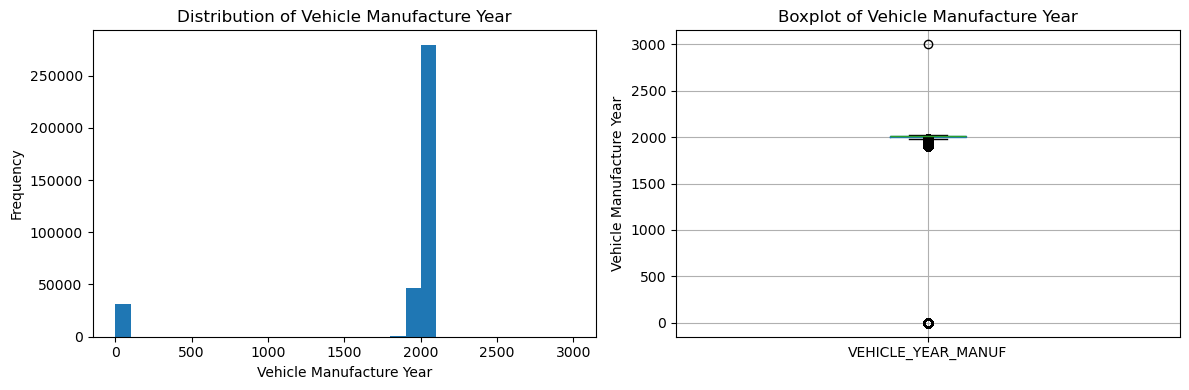

In [38]:
plot_distribution(vehicle_df, 'VEHICLE_YEAR_MANUF', 'Vehicle Manufacture Year', 30)

In [39]:
# Inspect vehicles with unusually strange year.
vehicle_df.loc[
    (vehicle_df['VEHICLE_YEAR_MANUF'] > 2025) | (vehicle_df['VEHICLE_YEAR_MANUF'] == 0 ),
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'VEHICLE_YEAR_MANUF'
    ]
].sort_values('VEHICLE_YEAR_MANUF', ascending=False)

,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_MAKE,VEHICLE_MODEL,VEHICLE_YEAR_MANUF
125682,T20150012401,B,Utility,HOLDEN,COMMOD,3001.0
244356,T20220023626,B,Car,TOYOTA,NaN,0.0
244344,T20220008182,A,Other Vehicle,UNKN,NaN,0.0
244343,T20220007031,B,Bicycle,NaN,NaN,0.0
244342,T20220004831,B,Bicycle,NaN,NaN,0.0
...,...,...,...,...,...,...
121141,T20140023522,B,Bicycle,NaN,NaN,0.0
121098,T20130003110,B,Not Known,UNKN,NaN,0.0
121044,T20250025520,A,Motor Cycle,HONDA,CRF,0.0
121037,T20250019907,B,Electric Device,UNKN,VITA X,0.0



**Findings**

- Many vehicles have a manufacture year of `0`, suggesting that the year was not recorded or is unknown. These values occur across multiple vehicle types, including cars, bicycles, motorcycles, and other vehicles.
- One vehicle has a manufacture year of `3001`, which is clearly invalid and may indicate a data entry error.

##### **Number of Cylinders (`NO_OF_CYLINDERS`)**

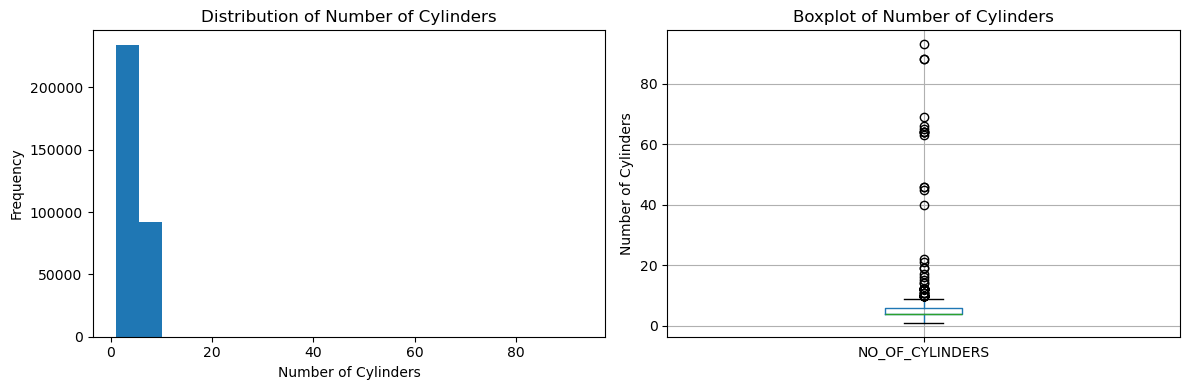

In [40]:
plot_distribution(vehicle_df, 'NO_OF_CYLINDERS', 'Number of Cylinders', 20)

In [41]:
# Inspect vehicles with unusually high no of cylinders.
vehicle_df.loc[
    vehicle_df['NO_OF_CYLINDERS'] > 20,
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'NO_OF_CYLINDERS'
    ]
].sort_values('NO_OF_CYLINDERS', ascending=False)

,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_MAKE,VEHICLE_MODEL,NO_OF_CYLINDERS
9660,T20140005298,A,Car,FORD,LASER,93.0
299904,T20140002743,C,Car,HOLDEN,COMMOD,88.0
262847,T20230017828,B,Car,HOLDEN,COMMOD,88.0
163925,T20240016762,A,Station Wagon,AUDI,Q7,69.0
31677,T20120017654,A,Utility,MITSUB,TRITON,66.0
122953,T20130023255,B,Car,FORD,FAIRLA,65.0
343682,T20190004933,A,Utility,HOLDEN,RODEO,64.0
189815,T20130012899,A,Utility,TOYOTA,HILUX,64.0
19512,T20140003721,B,Utility,HOLDEN,COMMOD,64.0
277821,T20120019850,A,Utility,FORD,COURIE,64.0



**Findings**

- Extreme values such as 93 (Ford Laser), 88 (Holden Commodore), and 64 (Toyota Hilux) are inconsistent with typical engine configurations for these vehicle models.


##### **Seating Capacity (`SEATING_CAPACITY`)**

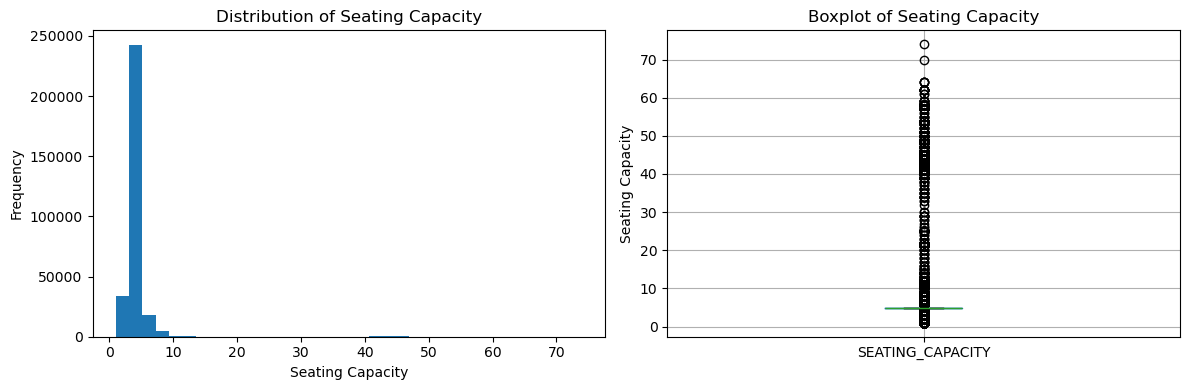

In [42]:
plot_distribution(vehicle_df, 'SEATING_CAPACITY', 'Seating Capacity', 35)

In [43]:
# Inspect vehicles with unusually high seating capacity counts.
vehicle_df.loc[
    vehicle_df['SEATING_CAPACITY'] > 20,
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'SEATING_CAPACITY'
    ]
].sort_values('SEATING_CAPACITY', ascending=False)

,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_MAKE,VEHICLE_MODEL,SEATING_CAPACITY
122395,T20220025163,A,Car,UNKN,C200,74.0
331437,T20140019204,A,Bus/Coach,SCANIA,L94UA,70.0
234002,T20160003645,A,Bus/Coach,BUST,NaN,64.0
101931,T20230022095,A,Bus/Coach,BUSTEC,NaN,64.0
13312,T20160004133,B,Bus/Coach,BUST,NaN,64.0
...,...,...,...,...,...,...
58342,T20160005571,A,Bus/Coach,TOYOTA,COASTE,21.0
317739,T20200000640,B,Bus/Coach,HINO,NaN,21.0
324903,T20120019724,B,Bus/Coach,TOYOTA,COASTE,21.0
166107,T20210017800,A,Mini Bus(9-13 seats),TOYOTA,COASTE,21.0



**Findings**

- Most vehicles with more than 20 seats are classified as `Bus/Coach`, making their higher seating capacities generally plausible.
- One vehicle classified as `Car` has a seating capacity of 74, which is inconsistent with typical passenger car characteristics.
- A vehicle classified as `Mini Bus (9-13 seats)` has a recorded seating capacity of 21, suggesting a potential inconsistency between its vehicle type and seating capacity.


##### **Total Number of Occupants (`TOTAL_NO_OCCUPANTS`)**

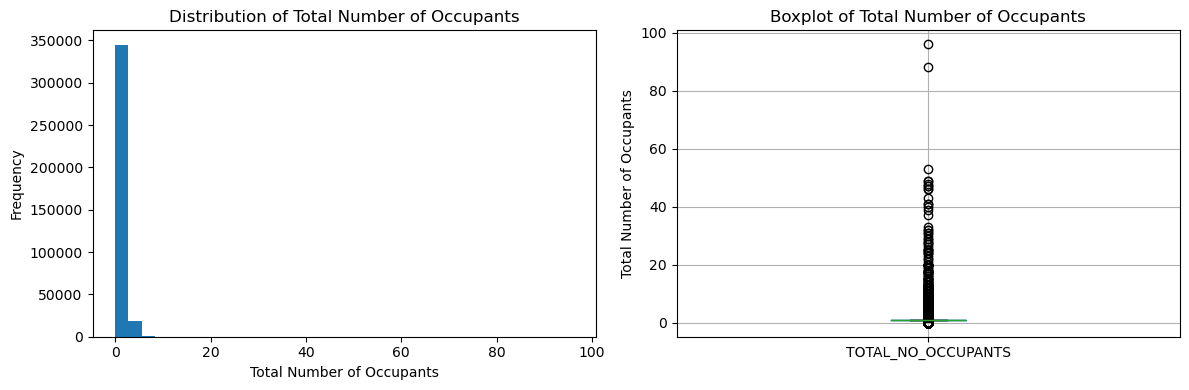

In [44]:
plot_distribution(vehicle_df, 'TOTAL_NO_OCCUPANTS', 'Total Number of Occupants', 35)

In [45]:
# Inspect vehicles with unusually high occupation counts.
vehicle_df.loc[
    vehicle_df['TOTAL_NO_OCCUPANTS'] > 20,
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'TOTAL_NO_OCCUPANTS'
    ]
].sort_values('TOTAL_NO_OCCUPANTS', ascending=False)

,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_MAKE,VEHICLE_MODEL,TOTAL_NO_OCCUPANTS
110539,T20130018492,B,Train,UNKN,NaN,96.0
314969,T20150016376,B,Train,UNKN,NaN,88.0
348511,T20170009983,B,Tram,UNKN,B-CLAS,53.0
52052,T20240013942,B,Bus/Coach,MERC B,0500RS,49.0
175864,T20190012874,B,Bus/Coach,SCANIA,K440EB,49.0
343854,T20140009807,A,Bus/Coach,VOLVO,B12BLE,48.0
163210,T20150020583,B,Bus/Coach,MERC B,OH1621,47.0
231522,T20150014941,A,Bus/Coach,VOLVO,B7RCA,47.0
354934,T20230011453,A,Bus/Coach,VOLVO,B7R,46.0
15740,T20240013942,C,Bus/Coach,MERC B,0500RS,46.0



**Findings**

- Most records with more than 20 occupants involve high-capacity transport vehicles, including trains, trams, and buses/coaches.
- High occupant counts are generally plausible for these vehicle categories and may explain some of the unusually high person counts observed in the Accident dataset.


In [46]:
# Inspect unusually low occupation counts.
vehicle_df.loc[
    (vehicle_df['TOTAL_NO_OCCUPANTS'] == 0),
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'TOTAL_NO_OCCUPANTS'
    ]
].sort_values('TOTAL_NO_OCCUPANTS', ascending=False)

vehicle_df[vehicle_df['TOTAL_NO_OCCUPANTS'] == 0]['VEHICLE_TYPE_DESC'].value_counts()

VEHICLE_TYPE_DESC
Car                                                   5265
Station Wagon                                         2559
Utility                                               1009
Panel Van                                              298
Light Commercial Vehicle (Rigid) <= 4.5 Tonnes GVM     270
Parked trailers                                        164
Heavy Vehicle (Rigid) > 4.5 Tonnes                     134
Not Known                                               70
Prime Mover - Single Trailer                            42
Other Vehicle                                           42
Taxi                                                    32
Prime Mover Only                                        24
Motor Cycle                                             23
Bus/Coach                                               22
Mini Bus(9-13 seats)                                    15
Bicycle                                                 14
Tram                                  


**Findings - Zero Occupancy Counts**

- Zero-occupant records occur across multiple vehicle types, including cars, station wagons, utilities, motorcycles, and parked trailers.
- Cars (5,265), station wagons (2,559), and utilities (1,009) account for a substantial number of these records.
- Zero occupants may be valid for certain vehicle types or circumstances, but may also reflect incomplete occupant information.


##### **Number of Wheels (`NO_OF_WHEELS`)**

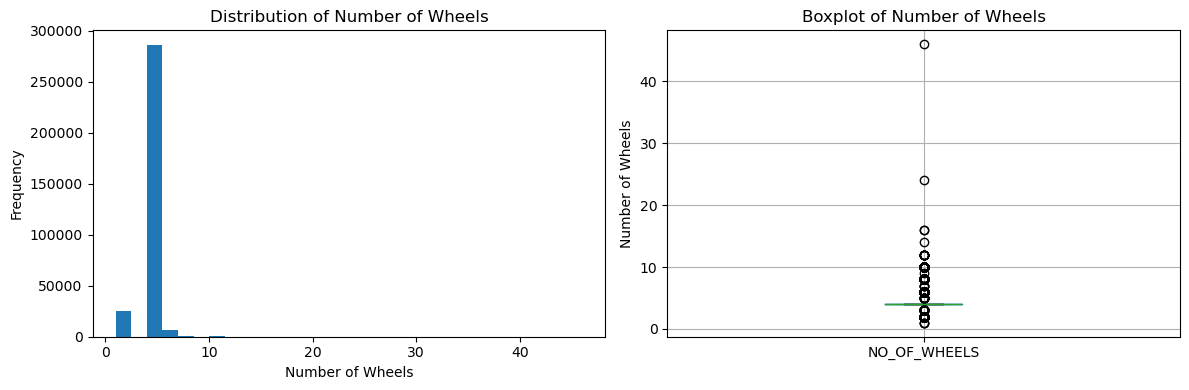

In [47]:
plot_distribution(vehicle_df, 'NO_OF_WHEELS', 'Number of Wheels', 30)

In [48]:
# Inspect vehicles with unusually high wheel counts.
vehicle_df.loc[
    vehicle_df['NO_OF_WHEELS'] > 12,
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'NO_OF_WHEELS'
    ]
].sort_values('NO_OF_WHEELS', ascending=False)

,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_MAKE,VEHICLE_MODEL,NO_OF_WHEELS
153743,T20120023815,A,Station Wagon,JEEP,CHEROK,46.0
255047,T20250019924,A,Station Wagon,NISSAN,PATROL,24.0
31572,T20220025927,A,Prime Mover - Single Trailer,BARRY,BARRY,16.0
274718,T20210011416,B,Heavy Vehicle (Rigid) > 4.5 Tonnes,TUFF T,TRAILE,16.0
118582,T20220005267,A,Prime Mover B-Double,W STAR,4864 F,14.0



**Findings**

- Two station wagons, a Jeep Cherokee and a Nissan Patrol, have recorded wheel counts of 46 and 24, respectively. These values are inconsistent with typical configurations for these vehicle types and suggest potential data entry errors.
- Higher wheel counts of 14-16 appear in heavy vehicles and prime movers, where such values may be plausible depending on vehicle configuration.


##### **Tare Weigh (`TARE_WEIGHT`)**

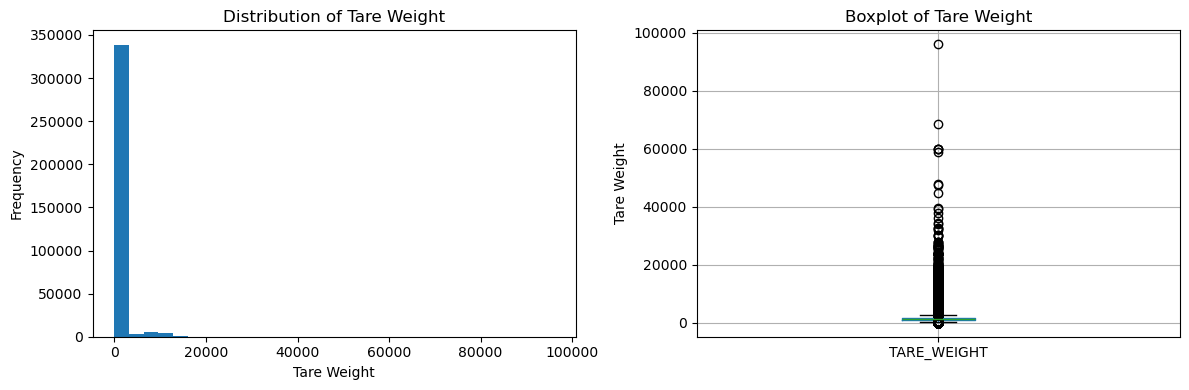

In [49]:
plot_distribution(vehicle_df, 'TARE_WEIGHT', 'Tare Weight', 30)

In [50]:
# Inspect unusually low or high tare weights.
vehicle_df.loc[
    (vehicle_df['TARE_WEIGHT'] > 20000),
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'TARE_WEIGHT'
    ]
].sort_values('TARE_WEIGHT', ascending=False)

,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_MAKE,VEHICLE_MODEL,TARE_WEIGHT
185784,T20170019068,A,Prime Mover - Single Trailer,KENWTH,K200,96000.0
68803,T20160022516,B,Light Commercial Vehicle (Rigid) <= 4.5 Tonnes...,VOLVO,XCOUNT,68635.0
8274,T20180017615,A,Heavy Vehicle (Rigid) > 4.5 Tonnes,LIEBHR,LTM116,60000.0
20336,T20200002766,B,Heavy Vehicle (Rigid) > 4.5 Tonnes,LIEBHR,LTM11,60000.0
95629,T20250000783,B,Heavy Vehicle (Rigid) > 4.5 Tonnes,DEMAG,AC1001,60000.0
...,...,...,...,...,...,...
232793,T20170009798,B,Other Vehicle,HYNDAI,ELNTRA,20748.0
233162,T20160014111,D,Heavy Vehicle (Rigid) > 4.5 Tonnes,VOLVO,FM11,20660.0
347209,T20220028912,B,Other Vehicle,FRANNA,AT20,20490.0
198545,T20210013625,A,Heavy Vehicle (Rigid) > 4.5 Tonnes,SCANIA,R12404,20420.0


In [51]:
# Inspect unusually low or high tare weights.
vehicle_df.loc[
    (vehicle_df['TARE_WEIGHT'] == 0),
    [
        'ACCIDENT_NO',
        'VEHICLE_ID',
        'VEHICLE_TYPE_DESC',
        'VEHICLE_MAKE',
        'VEHICLE_MODEL',
        'TARE_WEIGHT'
    ]
].sort_values('TARE_WEIGHT', ascending=False)

vehicle_df[vehicle_df['TARE_WEIGHT'] == 0]['VEHICLE_TYPE_DESC'].value_counts()

VEHICLE_TYPE_DESC
Motor Cycle                                           21177
Bicycle                                               15827
Not Known                                              5187
Car                                                    3928
Motor Scooter                                          1395
Station Wagon                                          1001
Other Vehicle                                           778
Tram                                                    618
Utility                                                 456
Electric Device                                         422
Panel Van                                               140
Bus/Coach                                                80
Prime Mover - Single Trailer                             80
Taxi                                                     78
Moped                                                    77
Heavy Vehicle (Rigid) > 4.5 Tonnes                       75
Quad Bike             


**Findings**

- Many high tare-weight records involve heavy vehicles, prime movers, and industrial machinery, for which higher weights may be plausible.
- Some records contain potentially implausible values, including a Volvo XC model recorded at 68,635 and a Hyundai Elantra at 20,748.
- The maximum value of 96,000 for a Kenworth prime mover also warrants further review, as the recorded tare weight may not reflect its actual unladen weight.
- Zero tare-weight values are present and require further assessment of their meaning.


### 2.5. Data Consistency & Validity

#### 2.5.1. Code Mapping

In [52]:
pairs_check = [
    ('VEHICLE_TYPE', 'VEHICLE_TYPE_DESC'),
    ('ROAD_SURFACE_TYPE', 'ROAD_SURFACE_TYPE_DESC'),
    ('TRAFFIC_CONTROL', 'TRAFFIC_CONTROL_DESC')
]

for code_col, desc_col in pairs_check:
    print(f"\n{code_col} vs {desc_col}")
    consistency_check = (
        vehicle_df[[code_col, desc_col]]
        .drop_duplicates()
        .sort_values(code_col))
    display(consistency_check)


VEHICLE_TYPE vs VEHICLE_TYPE_DESC


,VEHICLE_TYPE,VEHICLE_TYPE_DESC
2,1,Car
1,2,Station Wagon
35,3,Taxi
12,4,Utility
4,5,Panel Van
6953,6,Prime Mover (No of Trailers Unknown)
4967,7,Rigid Truck(Weight Unknown)
63,8,Bus/Coach
1494,9,Mini Bus(9-13 seats)
8,10,Motor Cycle



ROAD_SURFACE_TYPE vs ROAD_SURFACE_TYPE_DESC


,ROAD_SURFACE_TYPE,ROAD_SURFACE_TYPE_DESC
1,1.0,Paved
528,2.0,Unpaved
0,3.0,Gravel
265,9.0,Not known
16080,NaN,NaN



TRAFFIC_CONTROL vs TRAFFIC_CONTROL_DESC


,TRAFFIC_CONTROL,TRAFFIC_CONTROL_DESC
0,0.0,No control
3,1.0,Stop-go lights
784,2.0,Flashing lights
620,3.0,Out of order
332,4.0,Ped. lights
221,5.0,Ped. crossing
6,6.0,RX Gates/Booms
14253,7.0,RX Bells/Lights
19462,8.0,RX No control
13,9.0,Roundabout



**Findings**

- No inconsistent code-description mappings were found for vehicle type, road surface type, or traffic control.
- Each code maps to a single description in the dataset.


#### 2.5.2. Logic Check

In [53]:
# Select records with both seating capacity and occupant count available.

valid_occupancy = vehicle_df[
    vehicle_df['SEATING_CAPACITY'].notna() &
    vehicle_df['TOTAL_NO_OCCUPANTS'].notna()
]

print(
    "Within capacity:",
    (valid_occupancy['TOTAL_NO_OCCUPANTS'] <
     valid_occupancy['SEATING_CAPACITY']).sum()
)

print(
    "Full capacity:",
    (valid_occupancy['TOTAL_NO_OCCUPANTS'] ==
     valid_occupancy['SEATING_CAPACITY']).sum()
)

print(
    "Over capacity:",
    (valid_occupancy['TOTAL_NO_OCCUPANTS'] >
     valid_occupancy['SEATING_CAPACITY']).sum()
)

Within capacity: 297322
Full capacity: 3884
Over capacity: 253


In [54]:
# Identify records that cannot be reliably assessed due to missing occupancy information.

cannot_assess = vehicle_df[
    vehicle_df['SEATING_CAPACITY'].isna() |
    vehicle_df['TOTAL_NO_OCCUPANTS'].isna()
]

print("Cannot reliably assess:", len(cannot_assess))

Cannot reliably assess: 62838



**Findings**

- Of 364,297 vehicle records, 297,322 have fewer occupants than seats, while 3,884 have occupants equal to seating capacity.
- 253 records have more occupants than seats. These are not necessarily errors, as some vehicle types may allow standing passengers.
- 62,838 records cannot be assessed because seating capacity or occupant information is missing.
- Missing seating capacity is the main reason why some records cannot be assessed.


## 3. Cross-data validation

In [55]:
# Count Accident records without any matching Vehicle record.
accident_without_vehicle = accident_df.loc[
    ~accident_df['ACCIDENT_NO'].isin(vehicle_df['ACCIDENT_NO'])
]

print("Accident records without Vehicle:", len(accident_without_vehicle))


# Count Vehicle records without any matching Accident record.
vehicle_without_accident = vehicle_df.loc[
    ~vehicle_df['ACCIDENT_NO'].isin(accident_df['ACCIDENT_NO'])
]

print("Vehicle records without Accident:", len(vehicle_without_accident))

Accident records without Vehicle: 9
Vehicle records without Accident: 0


In [56]:
# Count actual Vehicle records for each accident.
actual_vehicle_counts = (
    vehicle_df
    .groupby('ACCIDENT_NO')
    .size()
    .rename('ACTUAL_VEHICLE_COUNT')
)

# Compare reported and actual vehicle counts.
vehicle_count_check = (
    accident_df[
        ['ACCIDENT_NO', 'NO_OF_VEHICLES', 'ACCIDENT_TYPE_DESC', 'NO_PERSONS']
    ]
    .merge(
        actual_vehicle_counts,
        on='ACCIDENT_NO',
        how='left'
    )
)

vehicle_count_check['ACTUAL_VEHICLE_COUNT'] = (
    vehicle_count_check['ACTUAL_VEHICLE_COUNT']
    .fillna(0)
    .astype(int)
)

vehicle_count_mismatch = vehicle_count_check.loc[
    vehicle_count_check['NO_OF_VEHICLES']
    != vehicle_count_check['ACTUAL_VEHICLE_COUNT']
]

print("Vehicle count mismatches:", len(vehicle_count_mismatch))

vehicle_count_mismatch

Vehicle count mismatches: 4


,ACCIDENT_NO,NO_OF_VEHICLES,ACCIDENT_TYPE_DESC,NO_PERSONS,ACTUAL_VEHICLE_COUNT
160605,T20230009098,1,collision with some other object,1,0
166008,T20250030921,2,Collision with vehicle,4,3
170899,T20210022607,1,Vehicle overturned (no collision),1,0
197188,T20210022263,1,Vehicle overturned (no collision),1,0


In [57]:
# Inspect Accident records with no matching Vehicle record.
accident_without_vehicle[
    [
        'ACCIDENT_NO',
        'ACCIDENT_TYPE_DESC',
        'NO_OF_VEHICLES',
        'NO_PERSONS',
        'NO_PERSONS_KILLED',
        'NO_PERSONS_INJ_2',
        'NO_PERSONS_INJ_3',
        'SEVERITY'
    ]
].sort_values('NO_OF_VEHICLES')

,ACCIDENT_NO,ACCIDENT_TYPE_DESC,NO_OF_VEHICLES,NO_PERSONS,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,SEVERITY
48927,T20200012731,Vehicle overturned (no collision),0,1,0,1,0,2
62271,T20220002330,Collision with a fixed object,0,1,0,0,1,3
62428,T20200008868,Vehicle overturned (no collision),0,1,0,1,0,2
127646,T20190002653,Vehicle overturned (no collision),0,1,0,0,1,3
142959,T20230030888,Vehicle overturned (no collision),0,1,0,0,1,3
162351,T20230027118,Vehicle overturned (no collision),0,1,0,1,0,2
160605,T20230009098,collision with some other object,1,1,0,0,1,3
170899,T20210022607,Vehicle overturned (no collision),1,1,0,0,1,3
197188,T20210022263,Vehicle overturned (no collision),1,1,0,0,1,3


In [58]:
# Select Accident records with high person counts.
high_person_accidents = accident_df.loc[
    accident_df['NO_PERSONS'] >= 20,
    ['ACCIDENT_NO', 'NO_PERSONS', 'NO_OF_VEHICLES']
]

# Join with Vehicle data to inspect involved vehicle types.
high_person_vehicle_check = (
    high_person_accidents
    .merge(
        vehicle_df[
            [
                'ACCIDENT_NO',
                'VEHICLE_ID',
                'VEHICLE_TYPE_DESC',
                'SEATING_CAPACITY',
                'TOTAL_NO_OCCUPANTS'
            ]
        ],
        on='ACCIDENT_NO',
        how='left'
    )
    .sort_values(
        ['NO_PERSONS', 'ACCIDENT_NO'],
        ascending=[False, True]
    )
)

# Summarise vehicles involved in each high-person accident.
high_person_summary = (
    high_person_vehicle_check
    .groupby(
        ['ACCIDENT_NO', 'NO_PERSONS', 'NO_OF_VEHICLES']
    )
    .agg(
        VEHICLE_TYPES=(
            'VEHICLE_TYPE_DESC',
            lambda x: ', '.join(x.dropna().astype(str))
        ),
        VEHICLE_OCCUPANTS=(
            'TOTAL_NO_OCCUPANTS',
            lambda x: list(x.dropna())
        )
    )
    .reset_index()
    .sort_values('NO_PERSONS', ascending=False)
)

high_person_summary.head(20)

,ACCIDENT_NO,NO_PERSONS,NO_OF_VEHICLES,VEHICLE_TYPES,VEHICLE_OCCUPANTS
2,T20130018492,97,2,"Train, Prime Mover - Single Trailer","[96.0, 1.0]"
53,T20240013942,96,3,"Bus/Coach, Bus/Coach, Station Wagon","[46.0, 49.0, 1.0]"
14,T20150016376,89,2,"Car, Train","[1.0, 88.0]"
26,T20170009983,54,2,"Heavy Vehicle (Rigid) > 4.5 Tonnes, Tram","[1.0, 53.0]"
31,T20190012874,51,2,"Prime Mover B-Double, Bus/Coach","[2.0, 49.0]"
5,T20140009807,50,2,Light Commercial Vehicle (Rigid) <= 4.5 Tonnes...,"[2.0, 48.0]"
13,T20150014941,48,2,"Bus/Coach, Station Wagon","[47.0, 1.0]"
17,T20150020583,48,2,"Prime Mover - Single Trailer, Bus/Coach","[1.0, 47.0]"
48,T20230011453,47,2,"Bus/Coach, Heavy Vehicle (Rigid) > 4.5 Tonnes","[46.0, 1.0]"
45,T20220018463,45,4,"Car, Car, Bus/Coach, Car","[1.0, 1.0, 40.0, 3.0]"


In [59]:
# Extract accident years from accident dates
accident_years = accident_df[["ACCIDENT_NO", "ACCIDENT_DATE"]].copy()

# Use the confirmed date format from the Accident profiling section
accident_years["ACCIDENT_YEAR"] = pd.to_datetime(
    accident_years["ACCIDENT_DATE"],
    errors="coerce",
    dayfirst=True
).dt.year

# Link vehicle records to their accident years
vehicle_year_check = vehicle_df[
    [
        "ACCIDENT_NO",
        "VEHICLE_ID",
        "VEHICLE_TYPE_DESC",
        "VEHICLE_YEAR_MANUF"
    ]
].merge(
    accident_years[["ACCIDENT_NO", "ACCIDENT_YEAR"]],
    on="ACCIDENT_NO",
    how="left",
    validate="many_to_one"
)

# Identify manufacture years later than accident years
future_manufacture_years = vehicle_year_check.loc[
    vehicle_year_check["VEHICLE_YEAR_MANUF"]
    > vehicle_year_check["ACCIDENT_YEAR"]
].copy()

print(
    "Manufacture years after accident year:",
    len(future_manufacture_years)
)

future_manufacture_years.sort_values(
    "VEHICLE_YEAR_MANUF",
    ascending=False
)


/tmp/ipykernel_406/3527421770.py:5: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  accident_years["ACCIDENT_YEAR"] = pd.to_datetime(


Manufacture years after accident year: 7


,ACCIDENT_NO,VEHICLE_ID,VEHICLE_TYPE_DESC,VEHICLE_YEAR_MANUF,ACCIDENT_YEAR
125682,T20150012401,B,Utility,3001.0,2015
149003,T20220008170,A,Utility,2022.0,2021
293048,T20220016159,A,Station Wagon,2020.0,2019
185825,T20190015310,B,Car,2019.0,2018
6286,T20160026014,A,Station Wagon,2016.0,2015
57896,T20140010573,D,Plant machinery and Agricultural equipment,2015.0,2014
75261,T20130009126,A,Station Wagon,2013.0,2012


**Findings**

- Nine accidents have no matching vehicle records, while all vehicle records have a matching accident.
- Four accidents have inconsistent reported and recorded vehicle counts.
- High-person-count accidents often involve buses, trains, or trams, helping explain the unusually high person counts found during profiling.
- Seven vehicles have manufacture years later than their corresponding accident years.
- One record has a manufacture year of `3001`, which is clearly invalid.
- The remaining six records have manufacture years one year after the accident year. These may be related to model-year reporting or data entry errors, but the exact cause cannot be confirmed from the available data.



## 4. Data Profiling Summary

The profiling covered 199,699 accident records and 364,297 vehicle records, focusing on missing values, duplicates, unusual values, and data consistency.

### Key Findings

| Area | Findings |
|---|---|
| **Duplicates** | No duplicate records or duplicate identifiers were found in either dataset. |
| **Missing Values** | The Accident dataset is largely complete, while several Vehicle attributes have high missing rates, particularly `VEHICLE_POWER`, `CARRY_CAPACITY`, `VEHICLE_WEIGHT`, and `CUBIC_CAPACITY`. |
| **Categorical Values** | Some attributes contain unknown or undocumented codes, including `DAY_OF_WEEK = 0` and different representations of unknown values in the Vehicle dataset. |
| **Numerical Values** | Several Vehicle attributes contain unusual values, such as invalid manufacture years, very high cylinder and wheel counts, and seating capacities that do not match typical vehicle types. |
| **Accident Consistency** | Person totals are consistent, but nine records have mismatches between accident severity and casualty outcomes. |
| **Vehicle Consistency** | 253 vehicle records have more occupants than seats, although some may be valid for vehicles allowing standing passengers. |
| **Cross-Dataset Consistency** | Nine accidents have no matching Vehicle records, and four accidents have mismatched vehicle counts. |
| **Manufacture Year** | Seven vehicles have manufacture years later than their corresponding accident years. |

### Next Step

The identified data quality issues will guide the cleaning and transformation process in `02_data_cleaning.ipynb`. The cleaning process will focus on handling missing and invalid values, standardising categories, and ensuring the datasets are ready for further analysis.
